WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
Streams >= 5 km2               rc=0     1.2 s
  to vector (5 km2)            rc=0     0.9 s
Streams >= 10 km2              rc=0     1.1 s
  to vector (10 km2)           rc=0     0.9 s
Streams >= 25 km2              rc=0     1.3 s
  to vector (25 km2)           rc=0     1.1 s


,threshold_km2,threshold_cells,segments,total_length_km,drainage_density_km_per_km2
0,5,5741,1269,3919.9,0.330
1,10,11481,637,2903.0,0.245
2,25,28703,269,1932.5,0.163


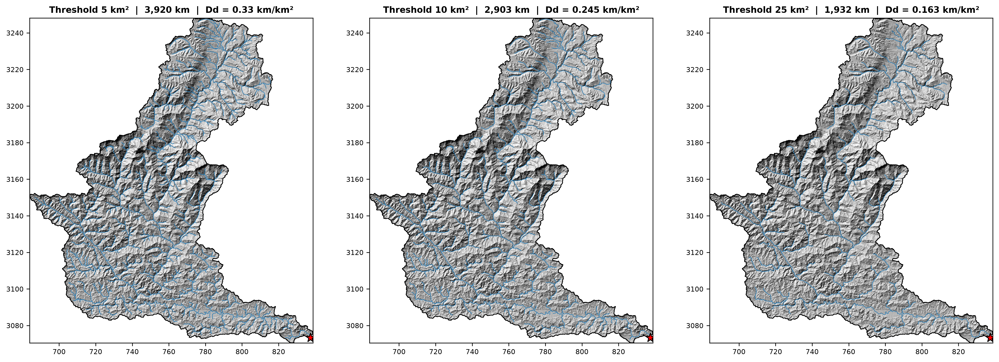

In [1]:
# ============================================================
# 04_Drainage.ipynb | Cell 1: setup + stream threshold comparison
# ============================================================
import importlib
import numpy as np
import geopandas as gpd
from whitebox import WhiteboxTools
import utils
importlib.reload(utils)
from utils import *

P = get_paths()
TMP = P.RAS / "_tmp"
TMP.mkdir(exist_ok=True)
wbt = WhiteboxTools()
wbt.set_working_dir(str(TMP))
wbt.set_verbose_mode(False)

ws = WatershedGrid(P.RAS / "watershed_mask.tif",
                   P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
print(ws)

ACC_KM2 = P.RAS / "flow_accumulation_km2.tif"     # clipped basin grid, values in km2
D8      = P.RAS / "d8_direction_codes.tif"        # clipped basin grid, whitebox codes
for p in (ACC_KM2, D8, P.RAS / "hillshade.tif"):
    assert p.exists(), f"missing: {p}"

THRESHOLDS_KM2 = [5, 10, 25]

# ---------- extract and vectorize ----------
streams, rows = {}, []
for t in THRESHOLDS_KM2:
    rast = TMP / f"streams_{t}km2.tif"
    vec  = TMP / f"streams_{t}km2.shp"
    wbt_run(f"Streams >= {t} km2", wbt.extract_streams, str(ACC_KM2), str(rast), float(t))
    wbt_run(f"  to vector ({t} km2)", wbt.raster_streams_to_vector, str(rast), str(D8), str(vec))
    g = gpd.read_file(vec)
    if g.crs is None:
        g = g.set_crs(ws.crs)
    streams[t] = g
    L = g.length.sum() / 1000
    rows.append(dict(threshold_km2=t, threshold_cells=round(t / ws.cell_area_km2),
                     segments=len(g), total_length_km=round(L, 1),
                     drainage_density_km_per_km2=round(L / ws.area_km2, 3)))
tab_thr = pd.DataFrame(rows)
save_table(tab_thr, P.TAB / "04_stream_threshold_test.csv")
display(tab_thr)

# ---------- side-by-side maps ----------
with rasterio.open(P.RAS / "hillshade.tif") as s:
    hs = s.read(1).astype("float32")
    nd = s.nodata
if nd is not None:
    hs[hs == nd] = np.nan

step = max(1, int(np.ceil(max(hs.shape) / 1800)))
km = FuncFormatter(lambda v, _: f"{v / 1000:.0f}")
fig, axs = plt.subplots(1, 3, figsize=(20, 7.5))
for ax, t, r in zip(axs, THRESHOLDS_KM2, rows):
    ax.imshow(hs[::step, ::step], extent=ws.extent, cmap="gray", vmin=0, vmax=255)
    ws.boundary.boundary.plot(ax=ax, color="k", lw=0.8)
    streams[t].plot(ax=ax, color="#1f78b4", linewidth=0.5)
    if ws.outlet is not None:
        ax.plot(*ws.outlet, marker="*", ms=11, mfc="red", mec="k", ls="none", zorder=6)
    ax.set_title(f"Threshold {t} km²  |  {r['total_length_km']:,.0f} km  |  "
                 f"Dd = {r['drainage_density_km_per_km2']} km/km²", fontsize=10, fontweight="bold")
    ax.xaxis.set_major_formatter(km); ax.yaxis.set_major_formatter(km)
    ax.set_xlim(ws.extent[0], ws.extent[1]); ax.set_ylim(ws.extent[2], ws.extent[3])
fig.savefig(P.FIG / "04_stream_threshold_comparison.png", dpi=200,
            bbox_inches="tight", facecolor="white")
plt.show()

Streams >= 5 km2               rc=0     1.3 s
Strahler order                 rc=0     1.4 s
Streams to vector              rc=0     1.0 s
Inferred D8 codes: {1: 'NE', 2: 'E', 4: 'SE', 8: 'S', 16: 'SW', 32: 'W', 64: 'NW', 128: 'N'}
Stream cells 112,718 | max order 5 | channel heads 635 (order-1 streams 635) | junction cells 634
Links: 1,269 | links without an order: 0 | total length 3,919.9 km


,order,streams_N,total_length_km,mean_length_km,bifurcation_ratio,length_ratio
0,1,635,1896.541,2.987,4.349,2.041
1,2,146,889.790,6.094,4.562,2.799
2,3,32,545.901,17.059,4.571,2.136
3,4,7,255.017,36.431,7.000,9.130
4,5,1,332.627,332.627,NaN,NaN


,metric,value
0,threshold_km2,5.0000
1,total_length_km,3919.8763
2,n_links,1269.0000
3,n_streams_all_orders,821.0000
4,max_order,5.0000
5,drainage_density_km_per_km2,0.3301
6,stream_frequency_per_km2,0.0691
7,mean_bifurcation_ratio,5.1205


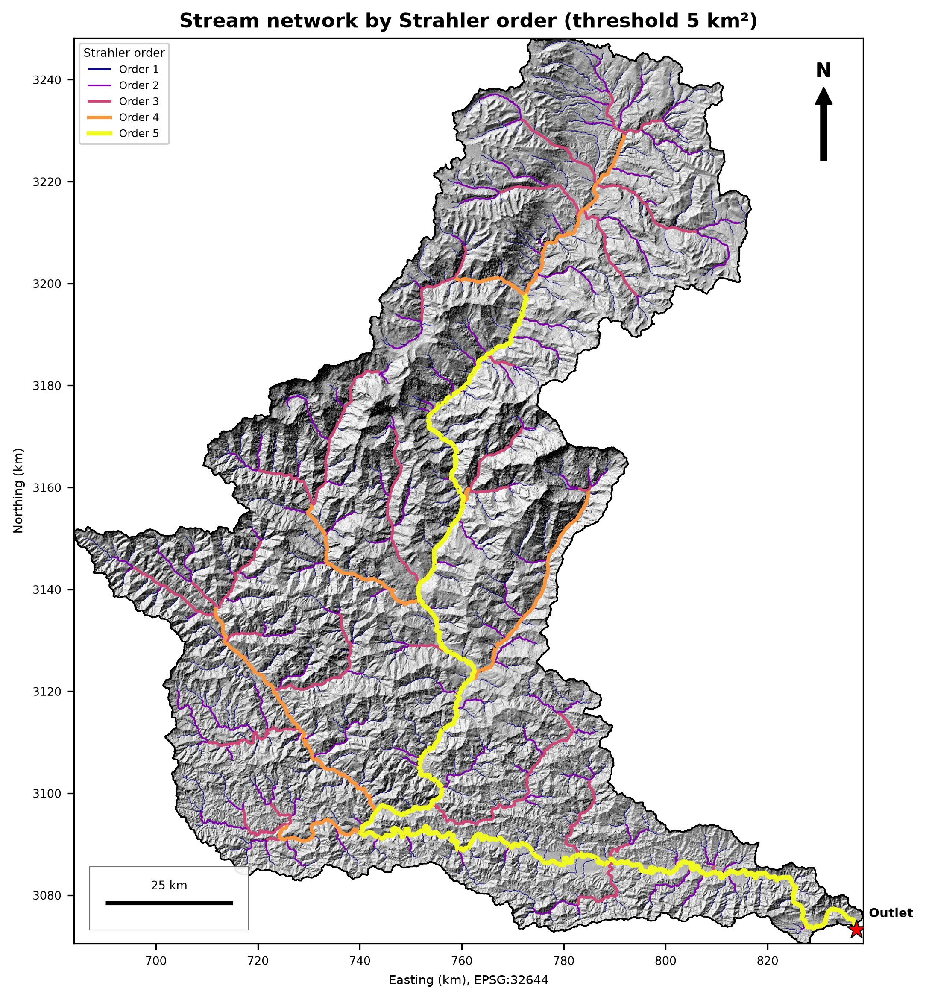

In [2]:
# ============================================================
# Cell 2: stream network, Strahler order, junctions, heads, statistics
# ============================================================
from matplotlib.lines import Line2D

STREAM_THRESHOLD_KM2 = 5          # <- change here if a different threshold looks better
T = STREAM_THRESHOLD_KM2

STR_TMP, ORD_TMP, VEC_TMP = TMP / "streams_sel.tif", TMP / "strahler_sel.tif", TMP / "streams_sel.shp"
wbt_run(f"Streams >= {T} km2", wbt.extract_streams, str(ACC_KM2), str(STR_TMP), float(T))
wbt_run("Strahler order",      wbt.strahler_stream_order, str(D8), str(STR_TMP), str(ORD_TMP))
wbt_run("Streams to vector",   wbt.raster_streams_to_vector, str(STR_TMP), str(D8), str(VEC_TMP))


def read_grid(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32"); nd = s.nodata; tf = s.transform
    if nd is not None:
        a[a == nd] = np.nan
    return a, tf

order, tf = read_grid(ORD_TMP)
order[order <= 0] = np.nan
acc, _ = read_grid(ACC_KM2)
d8, _  = read_grid(D8)
assert order.shape == ws.mask.shape == acc.shape, "grids differ - rerun notebooks 01-03 in order"
S = np.isfinite(order)
H, W = S.shape

# ---------- inflow counts from the D8 raster ----------
# ---------- infer the D8 code convention from the data (steepest descent on the conditioned DEM) ----------
dem_c = ws.read(P.RAS / "dem_conditioned.tif")
OFFS  = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
NAMES = {(-1, 0): "N", (-1, 1): "NE", (0, 1): "E", (1, 1): "SE",
         (1, 0): "S", (1, -1): "SW", (0, -1): "W", (-1, -1): "NW"}
rng, dest = np.random.default_rng(0), {}
for code in (1, 2, 4, 8, 16, 32, 64, 128):
    rr, cc = np.nonzero(d8 == code)
    pick = rng.choice(len(rr), min(len(rr), 200_000), replace=False)
    rr, cc = rr[pick], cc[pick]
    slopes = [np.nanmean((dem_c[rr, cc] - dem_c[np.clip(rr + dr, 0, H - 1),
                                                np.clip(cc + dc, 0, W - 1)]) / np.hypot(dr, dc))
              for dr, dc in OFFS]
    dest[code] = OFFS[int(np.nanargmax(slopes))]
assert len(set(dest.values())) == 8, "could not infer a unique direction for every code"
print("Inferred D8 codes:", {c: NAMES[o] for c, o in dest.items()})
back = {(-dr, -dc): code for code, (dr, dc) in dest.items()}   # neighbour offset -> code that flows into the cell
del dem_c

n_up = np.zeros(S.shape, "uint8")          # stream neighbours draining into each cell
same_up = np.zeros(S.shape, "uint8")       # ... of the same Strahler order
for (dr, dc), code in back.items():
    rc_, cc_ = slice(max(0, -dr), H - max(0, dr)), slice(max(0, -dc), W - max(0, dc))
    rn_, cn_ = slice(max(0, dr), H - max(0, -dr)), slice(max(0, dc), W - max(0, -dc))
    inflow = S[rn_, cn_] & (d8[rn_, cn_] == code) & S[rc_, cc_]
    n_up[rc_, cc_] += inflow
    same_up[rc_, cc_] += inflow & (order[rn_, cn_] == order[rc_, cc_])

orders = [int(u) for u in np.unique(order[S])]
N = {u: int(((order == u) & (same_up == 0)).sum()) for u in orders}   # Strahler streams per order
heads, junc = S & (n_up == 0), S & (n_up >= 2)
print(f"Stream cells {S.sum():,} | max order {max(orders)} | channel heads {heads.sum():,} "
      f"(order-1 streams {N[1]:,}) | junction cells {junc.sum():,}")

# ---------- vector lines with order and upstream area ----------
g = gpd.read_file(VEC_TMP)
if g.crs is None:
    g = g.set_crs(ws.crs)
g = g.reset_index(drop=True)

def sample(geom):
    if geom.geom_type != "LineString":
        geom = max(geom.geoms, key=lambda x: x.length)
    xy = np.asarray(geom.coords)
    r, c = rasterio.transform.rowcol(tf, xy[:, 0], xy[:, 1])
    r, c = np.clip(np.asarray(r), 0, H - 1), np.clip(np.asarray(c), 0, W - 1)
    o, a = order[r, c], acc[r, c]
    return (np.nanmin(o) if np.isfinite(o).any() else np.nan,
            np.nanmax(a) if np.isfinite(a).any() else np.nan)

vals = [sample(x) for x in g.geometry]
g["link_id"]   = np.arange(1, len(g) + 1)
g["order"]     = pd.Series([v[0] for v in vals]).round().astype("Int64")
g["upstr_km2"] = np.round([v[1] for v in vals], 3)
g["length_km"] = (g.length / 1000).round(4)
print(f"Links: {len(g):,} | links without an order: {int(g['order'].isna().sum())} | "
      f"total length {g.length_km.sum():,.1f} km")

# ---------- Strahler table + summary ----------
Ltot = g.groupby("order")["length_km"].sum()
tab = pd.DataFrame({"order": orders, "streams_N": [N[u] for u in orders],
                    "total_length_km": [float(Ltot.get(u, 0.0)) for u in orders]})
tab["mean_length_km"] = tab.total_length_km / tab.streams_N
tab["bifurcation_ratio"] = tab.streams_N / tab.streams_N.shift(-1)
tab["length_ratio"] = tab.mean_length_km.shift(-1) / tab.mean_length_km
tab = tab.round(3)
save_table(tab, P.TAB / "04_strahler_statistics.csv")
display(tab)

Lk, Nall = g.length_km.sum(), sum(N.values())
summ = pd.DataFrame({"metric": ["threshold_km2", "total_length_km", "n_links", "n_streams_all_orders",
                                "max_order", "drainage_density_km_per_km2", "stream_frequency_per_km2",
                                "mean_bifurcation_ratio"],
                     "value": [T, Lk, len(g), Nall, max(orders), Lk / ws.area_km2,
                               Nall / ws.area_km2, tab.bifurcation_ratio.mean()]}).round(4)
save_table(summ, P.TAB / "04_stream_summary.csv")
display(summ)

# ---------- save rasters and vectors ----------
ws.save(order, P.RAS / "stream_order.tif", nodata=0, dtype="uint8")
ws.save(np.where(S, 1.0, np.nan), P.RAS / "streams.tif", nodata=0, dtype="uint8")
g.to_file(P.VEC / "streams.gpkg", driver="GPKG"); g.to_file(P.VEC / "streams.shp")

def points(mask):
    r, c = np.where(mask)
    return gpd.GeoDataFrame({"order": order[r, c].astype(int), "n_in": n_up[r, c],
                             "upstr_km2": acc[r, c].round(3)},
                            geometry=gpd.points_from_xy(tf.c + (c + 0.5) * tf.a,
                                                        tf.f + (r + 0.5) * tf.e), crs=ws.crs)
for name, m in [("stream_junctions", junc), ("stream_heads", heads)]:
    gp = points(m)
    gp.to_file(P.VEC / f"{name}.gpkg", driver="GPKG"); gp.to_file(P.VEC / f"{name}.shp")

# ---------- map ----------
hs, _ = read_grid(P.RAS / "hillshade.tif")
assert hs.shape == ws.mask.shape, "hillshade is on a different grid - rerun notebook 02"
step = max(1, int(np.ceil(max(hs.shape) / 2500)))
e = ws.extent
fig, ax = plt.subplots(figsize=(8, 8 * (e[3] - e[2]) / (e[1] - e[0])))
ax.imshow(hs[::step, ::step], extent=e, cmap="gray", vmin=0, vmax=255)
cmap, top_o, handles = plt.get_cmap("plasma"), max(orders), []
for u in orders:
    col, lw = cmap((u - 1) / max(top_o - 1, 1)), 0.3 + 0.55 * (u - 1)
    g[g["order"] == u].plot(ax=ax, color=col, linewidth=lw)
    handles.append(Line2D([0], [0], color=col, lw=max(lw, 1.0), label=f"Order {u}"))
map_furniture(ax, ws, f"Stream network by Strahler order (threshold {T} km²)")
ax.legend(handles=handles, loc="upper left", title="Strahler order", fontsize=6,
          title_fontsize=6.5, framealpha=0.92)
fig.savefig(P.FIG / "04_stream_order.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [3]:
w = (tab.streams_N + tab.streams_N.shift(-1)).dropna()
rb_w = np.average(tab.bifurcation_ratio.dropna(), weights=w)
summ.loc[len(summ)] = ["weighted_mean_bifurcation_ratio", round(rb_w, 4)]
save_table(summ, P.TAB / "04_stream_summary.csv")
print(f"Weighted mean bifurcation ratio: {rb_w:.3f}")

Weighted mean bifurcation ratio: 4.416


HAND traced in 2 s
Basin cells without a HAND value: 0 (expect 0)
HAND min 0.000 m (expect >= 0) | max 5,688 m
Euclidean distance in 10 s


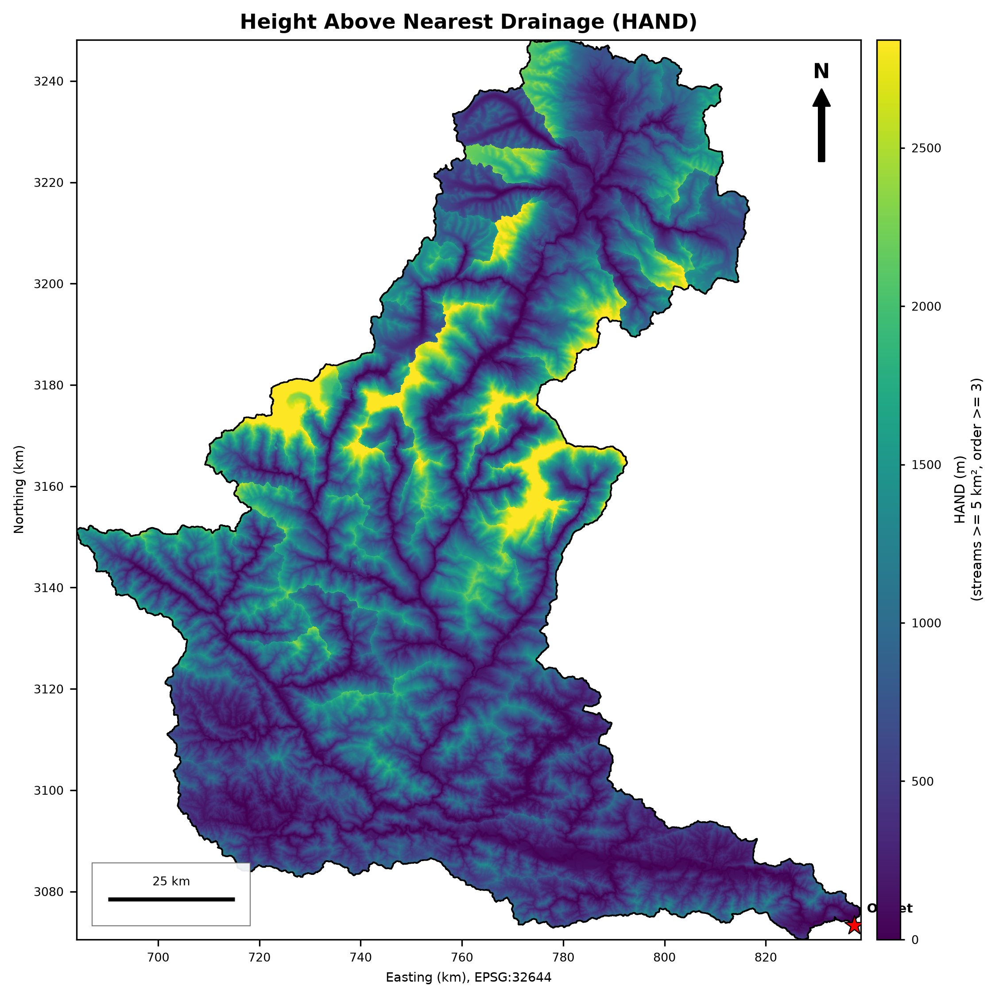

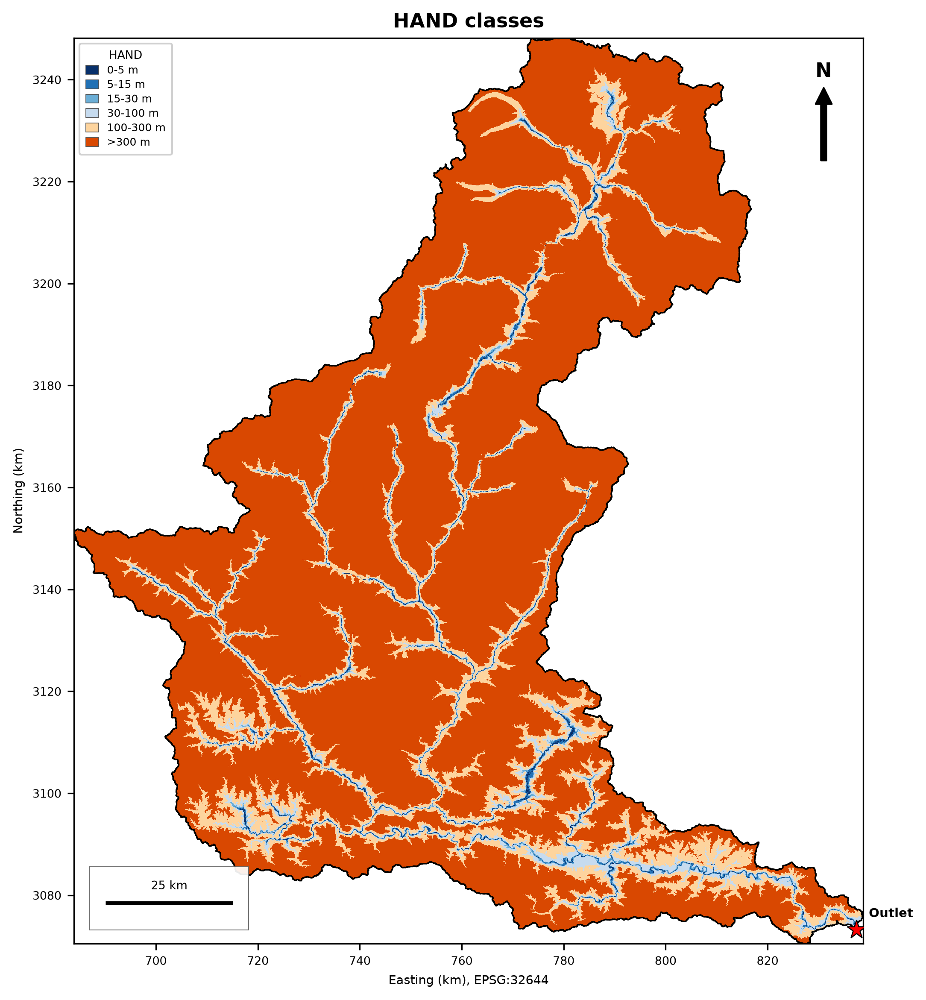

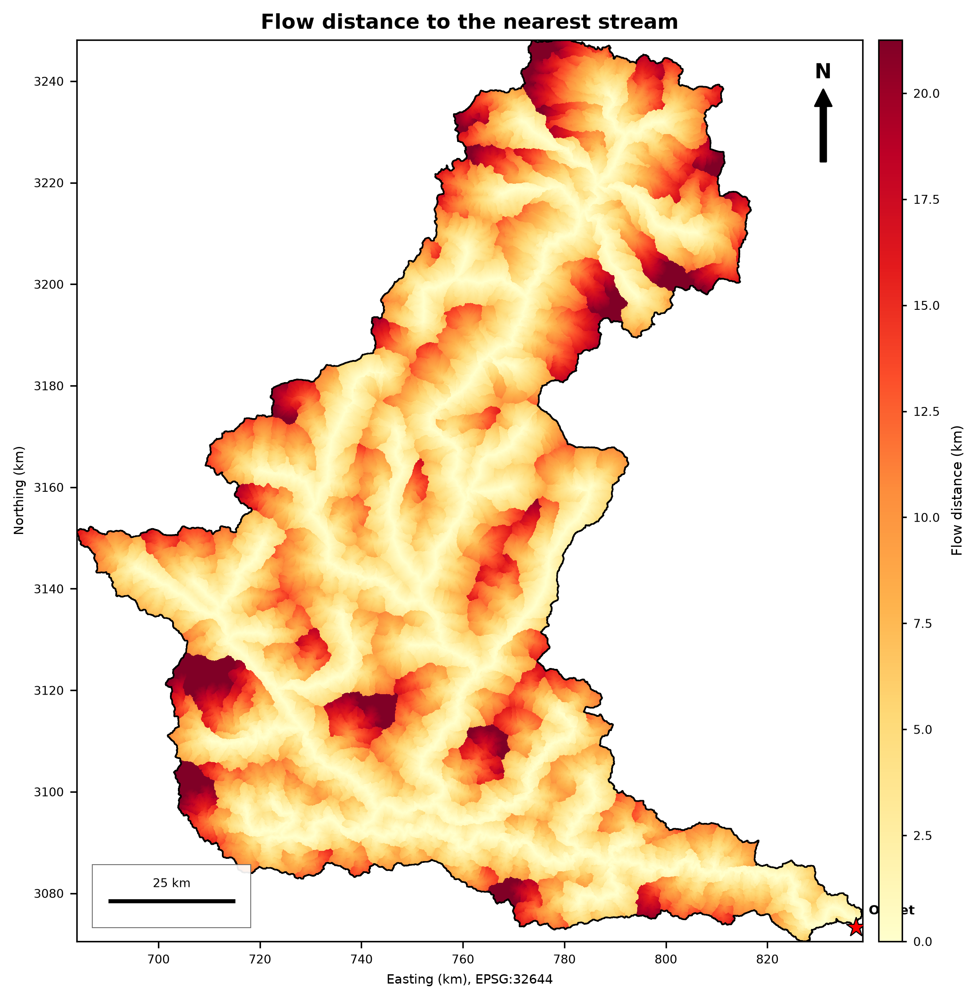

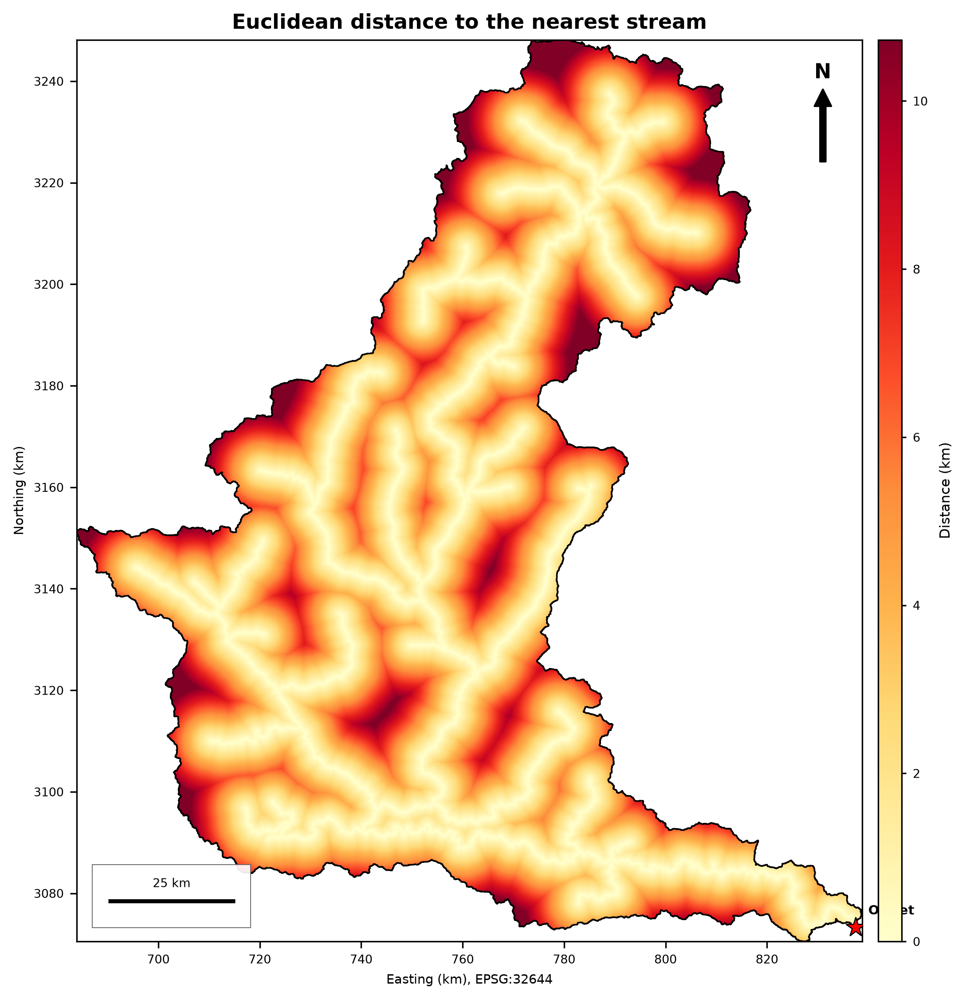

,class_id,label,cells,area_km2,percent
0,1,0-5 m,68979,60.08,0.51
1,2,5-15 m,96970,84.46,0.71
2,3,15-30 m,105577,91.96,0.77
3,4,30-100 m,485746,423.09,3.56
4,5,100-300 m,1826579,1590.95,13.40
5,6,>300 m,11047684,9622.55,81.05


,layer,min,mean,median,p98,max
0,hand_m,0.0,887.599976,724.000000,2841.000000,5688.000000
1,flow_distance_to_stream_m,0.0,6704.310059,5516.629883,21256.730469,35531.109375
2,euclid_distance_to_stream_m,0.0,3856.239990,3394.479980,10727.219727,16414.019531


HAND <= 15 m zone: 145.3 km2 (1.2 % of basin), 1 polygons


In [5]:
# ============================================================
# Cell 3: HAND, flow distance to stream, Euclidean distance to stream
# ============================================================
# needs Cells 1-2 run first (ws, read_grid, T, D8 path)
import numba
from scipy import ndimage

HAND_MIN_ORDER = 3                      # 1 = all streams at the threshold; 3 = only order 3+ channels
HAND_BREAKS = [5, 15, 30, 100, 300]
HAND_LABELS = ["0-5 m", "5-15 m", "15-30 m", "30-100 m", "100-300 m", ">300 m"]
HAND_COLORS = ["#08306b", "#2171b5", "#6baed6", "#c6dbef", "#fdd49e", "#d94801"]
FLOOD_HAND  = 15                        # m, near-channel zone polygon

# ---------- inputs ----------
order_r, _ = read_grid(P.RAS / "stream_order.tif")
S = np.isfinite(order_r) & (order_r >= HAND_MIN_ORDER)
d8, _ = read_grid(D8)
d8i = np.nan_to_num(d8, nan=0).astype("int16")
dem_c = ws.read(P.RAS / "dem_conditioned.tif")
acc_cells = ws.read(P.RAS / "flow_accumulation.tif")     # exact integer cell counts
H, W = S.shape
assert d8i.shape == dem_c.shape == acc_cells.shape == S.shape

# whitebox D8 code -> (drow, dcol) of the receiving cell (convention confirmed in Cell 2)
DR = np.zeros(256, np.int64); DC = np.zeros(256, np.int64)
for code, (dr, dc) in {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0),
                       16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}.items():
    DR[code], DC[code] = dr, dc

# order the cells so downstream cells come first (accumulation strictly increases downstream)
flat_acc = acc_cells.ravel()
idx = np.flatnonzero(np.isfinite(flat_acc))
idx = idx[np.argsort(-flat_acc[idx], kind="stable")]
del flat_acc

@numba.njit
def trace_to_stream(idx, d8, stream, dem, DR, DC, W, H, step_m, out_elev, out_dist):
    for k in range(idx.shape[0]):
        i = idx[k]
        r = i // W
        c = i % W
        if stream[r, c]:
            out_elev[r, c] = dem[r, c]
            out_dist[r, c] = 0.0
            continue
        code = d8[r, c]
        if code == 0:
            continue
        r2 = r + DR[code]
        c2 = c + DC[code]
        if r2 < 0 or r2 >= H or c2 < 0 or c2 >= W:
            continue
        if np.isnan(out_elev[r2, c2]):
            continue
        out_elev[r, c] = out_elev[r2, c2]
        s = step_m
        if DR[code] != 0 and DC[code] != 0:
            s = step_m * 1.4142135623730951
        out_dist[r, c] = out_dist[r2, c2] + s

t0 = time.time()
stream_elev = np.full(S.shape, np.nan, "float32")
fdist       = np.full(S.shape, np.nan, "float32")
trace_to_stream(idx, d8i, S, dem_c, DR, DC, W, H, float(ws.res[0]), stream_elev, fdist)
hand = dem_c - stream_elev
print(f"HAND traced in {time.time() - t0:.0f} s")
del idx, stream_elev

unresolved = int((ws.mask & ~np.isfinite(hand)).sum())
print(f"Basin cells without a HAND value: {unresolved:,} (expect 0)")
print(f"HAND min {np.nanmin(hand):.3f} m (expect >= 0) | max {np.nanmax(hand):,.0f} m")

# ---------- Euclidean distance to the nearest stream cell ----------
t0 = time.time()
edist = ndimage.distance_transform_edt(~S, sampling=float(ws.res[0])).astype("float32")
edist[~ws.mask] = np.nan
print(f"Euclidean distance in {time.time() - t0:.0f} s")

# ---------- save rasters ----------
hand_cls = classify(hand, HAND_BREAKS)
ws.save(hand,  P.RAS / "hand_m.tif")
ws.save(fdist, P.RAS / "flow_distance_to_stream_m.tif")
ws.save(edist, P.RAS / "euclid_distance_to_stream_m.tif")
ws.save(hand_cls, P.RAS / "hand_classes.tif", nodata=0, dtype="uint8")

# ---------- maps ----------
lab = f"streams >= {T} km², order >= {HAND_MIN_ORDER}"
make_map(hand, ws, P.FIG / "04_hand.png", title="Height Above Nearest Drainage (HAND)",
         label=f"HAND (m)\n({lab})", cmap="viridis", vmin=0, vmax=float(np.nanpercentile(hand, 98)))
make_map(hand_cls, ws, P.FIG / "04_hand_classes.png", title="HAND classes", label="HAND",
         classes=[(i + 1, HAND_LABELS[i], HAND_COLORS[i]) for i in range(len(HAND_LABELS))])
make_map(fdist / 1000, ws, P.FIG / "04_flow_distance_to_stream.png",
         title="Flow distance to the nearest stream", label="Flow distance (km)",
         cmap="YlOrRd", vmin=0)
make_map(edist / 1000, ws, P.FIG / "04_euclid_distance_to_stream.png",
         title="Euclidean distance to the nearest stream", label="Distance (km)",
         cmap="YlOrRd", vmin=0)

# ---------- tables ----------
tab_hand = class_table(hand_cls, HAND_LABELS, ws)
save_table(tab_hand, P.TAB / "04_hand_classes.csv")
display(tab_hand)

rows = []
for name, a in [("hand_m", hand), ("flow_distance_to_stream_m", fdist),
                ("euclid_distance_to_stream_m", edist)]:
    v = a[np.isfinite(a)]
    rows.append(dict(layer=name, min=v.min(), mean=v.mean(), median=np.median(v),
                     p98=np.percentile(v, 98), max=v.max()))
stats = pd.DataFrame(rows).round(2)
save_table(stats, P.TAB / "04_hand_distance_statistics.csv")
display(stats)

# ---------- vector: near-channel zone ----------
fl = np.where(np.isfinite(hand), hand <= FLOOD_HAND, False).astype("uint8")
polys = [shape(g) for g, v in features.shapes(fl, mask=fl.astype(bool),
                                              transform=ws.transform, connectivity=8)]
gz = gpd.GeoDataFrame({"area_km2": [p.area / 1e6 for p in polys]}, geometry=polys, crs=ws.crs)
gz["label"] = f"HAND <= {FLOOD_HAND} m"
gz.to_file(P.VEC / f"hand_le_{FLOOD_HAND}m.gpkg", driver="GPKG")
print(f"HAND <= {FLOOD_HAND} m zone: {gz.area_km2.sum():,.1f} km2 "
      f"({100 * gz.area_km2.sum() / ws.area_km2:.1f} % of basin), {len(gz):,} polygons")

In [10]:
# ============================================================
# Cell 4: main stem + subcatchments
# ============================================================
# needs Cells 1-2 run first (ws, wbt, TMP, ACC_KM2, D8, read_grid) and the map_furniture helper in utils
from scipy import ndimage
from shapely.geometry import Point
from matplotlib.lines import Line2D

SUBBASIN_THRESHOLD_KM2 = 150     # stream threshold defining subcatchment links (n_links ~ 0.54 * area / threshold)

CODE_DIR = {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0), 16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}
INFLOW = {(-dr, -dc): code for code, (dr, dc) in CODE_DIR.items()}    # neighbour offset -> code draining into the cell

# ---------- inputs ----------
order_r, tf = read_grid(P.RAS / "stream_order.tif")
S_all = np.isfinite(order_r)
d8, _ = read_grid(D8)
d8i = np.nan_to_num(d8, nan=0).astype("int16")
len_up, _ = read_grid(P.RAS / "flow_length_upstream_max_m.tif")
slope_a, _ = read_grid(P.RAS / "slope_deg.tif")
dem_o, _ = read_grid(P.RAS / "dem.tif")
dem_c = ws.read(P.RAS / "dem_conditioned.tif")
acc_cells = ws.read(P.RAS / "flow_accumulation.tif")
H, W = S_all.shape
assert d8i.shape == len_up.shape == dem_o.shape == dem_c.shape == acc_cells.shape == (H, W), \
    "grids differ - rerun notebooks 01-03 in order"

# ============ 1) main stem ============
r, c = np.unravel_index(np.nanargmax(acc_cells), acc_cells.shape)     # outlet = cell with the largest accumulation
assert S_all[r, c], "outlet cell is not on the stream network"
path = [(r, c)]
while True:
    best, best_val = None, -1.0
    for (a, b), code in INFLOW.items():
        rn, cn = r + a, c + b
        if 0 <= rn < H and 0 <= cn < W and S_all[rn, cn] and d8i[rn, cn] == code:
            v = len_up[rn, cn] + ws.res[0] * (1.4142135623730951 if (a and b) else 1.0)
            if v > best_val:
                best, best_val = (rn, cn), v
    if best is None:
        break
    r, c = best
    path.append(best)

rr = np.array([p[0] for p in path])[::-1]                              # head -> outlet
cc = np.array([p[1] for p in path])[::-1]
xs, ys = tf.c + (cc + 0.5) * tf.a, tf.f + (rr + 0.5) * tf.e
d_head = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(xs), np.diff(ys)))])
total = float(d_head[-1])

prof = pd.DataFrame({"dist_from_outlet_m": total - d_head, "dist_from_head_m": d_head, "x": xs, "y": ys,
                     "elev_original_m": dem_o[rr, cc], "elev_conditioned_m": dem_c[rr, cc],
                     "upstr_area_km2": acc_cells[rr, cc] * ws.cell_area_km2, "order": order_r[rr, cc]})
save_table(prof.round(3), P.TAB / "04_main_stem_profile.csv")

lfp = gpd.read_file(P.VEC / "longest_flowpath.gpkg")
near = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=ws.crs).distance(lfp.geometry.union_all()) < 2 * ws.res[0]
head_e, out_e = float(dem_o[rr[0], cc[0]]), float(dem_o[rr[-1], cc[-1]])
print(f"Main stem: {total / 1000:,.1f} km | longest flowpath: {lfp.length.sum() / 1000:,.1f} km "
      f"(overland part above the channel head: {lfp.length.sum() / 1000 - total / 1000:,.1f} km)")
print(f"Head {head_e:,.0f} m (area {prof.upstr_area_km2.iloc[0]:.1f} km2) -> outlet {out_e:,.0f} m | "
      f"mean gradient {(head_e - out_e) / total:.4f} m/m")
print(f"Main stem lies on the longest flowpath for {100 * near.mean():.1f} % of its length")

stem = gpd.GeoDataFrame({"len_km": [round(total / 1000, 3)], "head_el_m": [head_e], "out_el_m": [out_e],
                         "drop_m": [head_e - out_e], "grad": [round((head_e - out_e) / total, 5)],
                         "head_km2": [round(float(prof.upstr_area_km2.iloc[0]), 2)]},
                        geometry=[LineString(np.column_stack([xs, ys]))], crs=ws.crs)
stem.to_file(P.VEC / "main_stem.gpkg", driver="GPKG"); stem.to_file(P.VEC / "main_stem.shp")



Main stem: 417.9 km | longest flowpath: 422.3 km (overland part above the channel head: 4.4 km)
Head 5,636 m (area 6.3 km2) -> outlet 184 m | mean gradient 0.0130 m/m
Main stem lies on the longest flowpath for 100.0 % of its length


Streams >= 150 km2             rc=0     1.3 s
Subbasins                      rc=0     1.8 s
Raw subcatchments: 39 | smaller than 20 km2: 3
Merged 3 slivers | still below 20 km2: 0 (only possible for the outlet unit, which has nothing downstream)

Final subcatchments: 36 | unassigned basin cells: 0 (expect 0)
Sum of areas 11,873.1 km2 vs basin 11,873.1 km2
Outlet units: 1 (expect 1) | every downstream id < own id: True
Stream length assigned to units: 3,919.9 km vs network 3,919.9 km
Area (km2): min 32.2 | median 322.6 | mean 329.8 | max 854.0
Units on the main stem: 13


,sub_id,down_id,area_km2,upstr_area_km2,elev_mean_m,slope_mean_deg,flowpath_length_km,n_merged
3,4,3,32.1713,9669.618164,966.0332,28.3773,9.693000,0
11,12,10,33.1015,1421.570435,3607.5192,17.2078,13.190200,1
12,13,11,40.8378,1220.114746,1175.4256,28.7195,14.394200,0
4,5,4,54.7686,7642.980957,1005.4464,29.2104,16.530001,0
15,16,12,110.4787,753.317993,4216.6206,22.5633,22.816900,0
1,2,1,152.3417,11048.736328,717.8583,20.8966,22.524799,0
35,36,2,198.5126,198.512604,925.3697,26.1659,32.931499,0
34,35,1,227.3593,227.359299,979.0025,27.0868,48.301399,0


,original_unit,original_area_km2,merged_into_sub_id
0,38,0.028,12
1,36,5.649,10
2,29,10.502,7


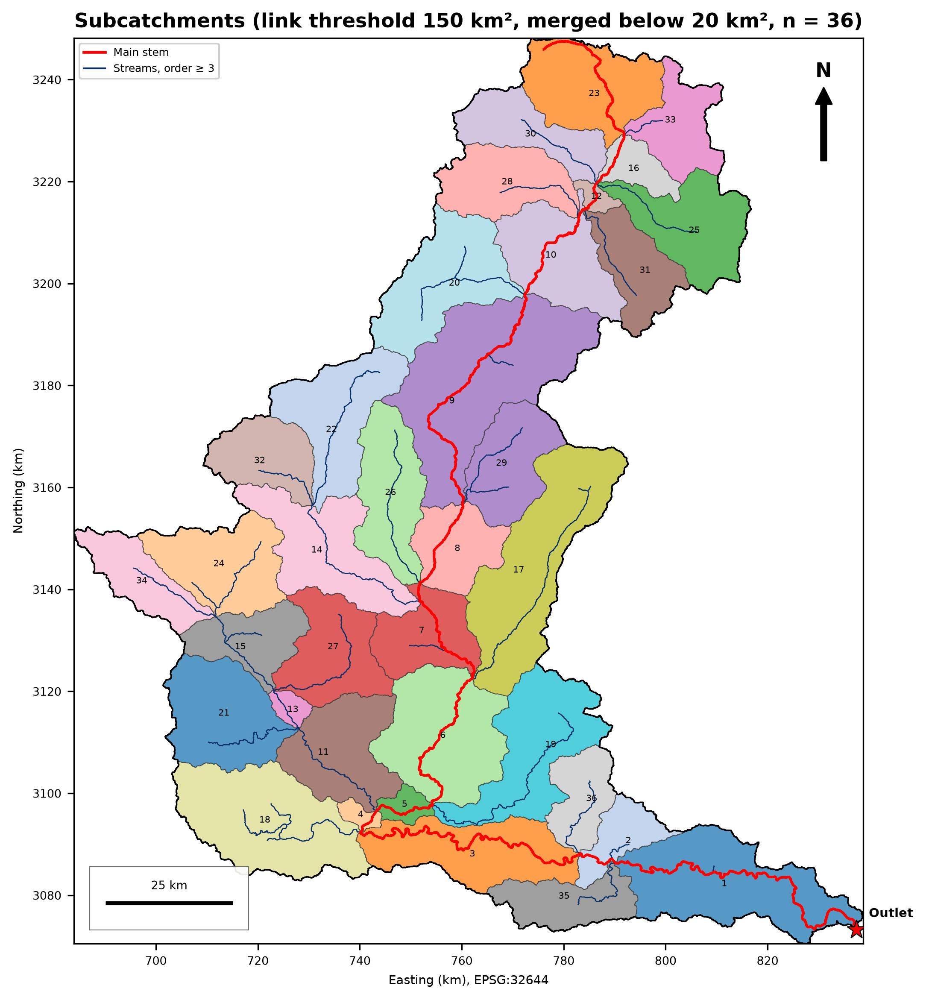

In [11]:
# ============================================================
# Cell 5: subcatchments (150 km2 links) + merge slivers < 20 km2 downstream + full CSV
# ============================================================
# needs Cells 1-2 (ws, wbt, TMP, P, ACC_KM2, D8, read_grid) and Cell 4 (main_stem.gpkg); map_furniture is in utils
from scipy import ndimage
from pyproj import Transformer
from matplotlib.lines import Line2D

SUBBASIN_THRESHOLD_KM2 = 150      # stream threshold that defines the subcatchment links
MIN_AREA_KM2           = 20       # smaller units are merged into their downstream neighbour

CODE_DIR = {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0), 16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}
to_ll = Transformer.from_crs(ws.crs, 4326, always_xy=True)

# ---------- inputs on the clipped basin grid ----------
d8, tf = read_grid(D8)
d8i = np.nan_to_num(d8, nan=0).astype("int16"); del d8
acc_cells = ws.read(P.RAS / "flow_accumulation.tif")
accf = np.nan_to_num(acc_cells, nan=-1.0)
H, W = d8i.shape
assert acc_cells.shape == (H, W), "grids differ - rerun notebooks 01-03 in order"

def grid(name):
    p = P.RAS / name
    if not p.exists():
        return None
    a, _ = read_grid(p)
    assert a.shape == (H, W), f"{name} is on a different grid - rerun notebooks 01-04 in order"
    return a

dem_o, slope_a, len_dn = grid("dem.tif"), grid("slope_deg.tif"), grid("flow_length_downstream_m.tif")
extra = {n: grid(f) for n, f in [("twi", "twi.tif"), ("hand_m", "hand_m.tif"),
                                 ("tri_m", "tri.tif"), ("relief_1km_m", "relative_relief.tif")]}
extra = {k: v for k, v in extra.items() if v is not None}

# ============ 1) raw subcatchments ============
SUB_STR, SUB_TMP = TMP / "streams_sub.tif", TMP / "subbasins_raw.tif"
wbt_run(f"Streams >= {SUBBASIN_THRESHOLD_KM2} km2", wbt.extract_streams,
        str(ACC_KM2), str(SUB_STR), float(SUBBASIN_THRESHOLD_KM2))
wbt_run("Subbasins", wbt.subbasins, str(D8), str(SUB_STR), str(SUB_TMP))
raw, _ = read_grid(SUB_TMP)
raw = np.where(np.isfinite(raw) & ws.mask, raw, 0).astype("int64")
ids_raw = np.unique(raw[raw > 0])
sub = np.where(raw > 0, np.searchsorted(ids_raw, raw) + 1, 0).astype("int32")
del raw
n0 = len(ids_raw)

def outlets_and_down(lbl, k):
    """Unit outlet = cell of maximum accumulation; downstream unit = the unit its D8 step enters."""
    ids_ = np.arange(1, k + 1)
    pos = np.array(ndimage.maximum_position(accf, lbl, ids_))
    orr_, occ_ = pos[:, 0], pos[:, 1]
    dn = np.zeros(k + 1, dtype=int)
    for j in ids_:
        code = int(d8i[orr_[j - 1], occ_[j - 1]])
        if code:
            dr, dc = CODE_DIR[code]
            r2, c2 = orr_[j - 1] + dr, occ_[j - 1] + dc
            if 0 <= r2 < H and 0 <= c2 < W and lbl[r2, c2] not in (0, j):
                dn[j] = lbl[r2, c2]
    return orr_, occ_, dn

cnt0 = np.bincount(sub.ravel(), minlength=n0 + 1)
area = cnt0 * ws.cell_area_km2
orr0, occ0, down = outlets_and_down(sub, n0)
print(f"Raw subcatchments: {n0} | smaller than {MIN_AREA_KM2} km2: {int((area[1:] < MIN_AREA_KM2).sum())}")

# ============ 2) merge slivers into the downstream neighbour (smallest first, repeat) ============
alive = np.ones(n0 + 1, bool); alive[0] = False
target = np.arange(n0 + 1)
merge_log = []
while True:
    cand = np.flatnonzero(alive & (area < MIN_AREA_KM2) & (down > 0))
    if cand.size == 0:
        break
    k = int(cand[np.argmin(area[cand])])
    d = int(down[k])
    area[d] += area[k]; area[k] = 0.0
    alive[k] = False
    target[target == k] = d          # everything already merged into k follows it
    down[down == k] = d              # units that drained into k now drain into d
    merge_log.append((k, d))
left = int((alive & (area < MIN_AREA_KM2)).sum())
print(f"Merged {len(merge_log)} slivers | still below {MIN_AREA_KM2} km2: {left} "
      f"(only possible for the outlet unit, which has nothing downstream)")

# ---------- renumber: outlet unit = 1, downstream ids are always smaller than upstream ids ----------
out_acc0 = acc_cells[orr0, occ0]
alive_ids = np.flatnonzero(alive)
alive_ids = alive_ids[np.argsort(-out_acc0[alive_ids - 1], kind="stable")]
m = len(alive_ids)
new_of_old = np.zeros(n0 + 1, dtype=np.int32)
new_of_old[alive_ids] = np.arange(1, m + 1)
lut = np.zeros(n0 + 1, dtype=np.int32)
lut[1:] = new_of_old[target[1:]]
subm = lut[sub]
del sub

ids = np.arange(1, m + 1)
cnt = np.bincount(subm.ravel(), minlength=m + 1)
orr, occ, down_f = outlets_and_down(subm, m)
print(f"\nFinal subcatchments: {m} | unassigned basin cells: {int((ws.mask & (subm == 0)).sum()):,} (expect 0)")
print(f"Sum of areas {cnt[1:].sum() * ws.cell_area_km2:,.1f} km2 vs basin {ws.area_km2:,.1f} km2")
ordered = all(down_f[j] < j for j in ids if down_f[j] > 0)
print(f"Outlet units: {int((down_f[1:] == 0).sum())} (expect 1) | every downstream id < own id: {ordered}")

# ============ 3) polygons ============
recs = {}
for geom, val in features.shapes(subm, mask=subm > 0, transform=ws.transform, connectivity=4):
    recs.setdefault(int(val), []).append(shape(geom))
gpoly = gpd.GeoSeries([MultiPolygon(recs[i]) for i in ids], crs=ws.crs)
perim_km = gpoly.simplify(ws.res[0]).length.values / 1000      # simplified by one cell to reduce raster-staircase length
cen = gpoly.centroid

def label_at(x, y):
    r_, c_ = (np.asarray(v) for v in rasterio.transform.rowcol(tf, np.asarray(x), np.asarray(y)))
    return subm[np.clip(r_, 0, H - 1), np.clip(c_, 0, W - 1)]

# ============ 4) attribute table ============
z = lambda a, f: np.asarray(f(a, labels=subm, index=ids))
A = cnt[1:] * ws.cell_area_km2
e_min, e_max, e_mean, e_med = (z(dem_o, f) for f in (ndimage.minimum, ndimage.maximum, ndimage.mean, ndimage.median))
L_m = z(len_dn, ndimage.maximum) - len_dn[orr, occ]                     # longest flowpath inside the unit
far = np.array(ndimage.maximum_position(np.nan_to_num(len_dn, nan=-1.0), subm, ids))
drop = dem_o[far[:, 0], far[:, 1]] - dem_o[orr, occ]
out_x, out_y = tf.c + (occ + 0.5) * tf.a, tf.f + (orr + 0.5) * tf.e
out_lon, out_lat = to_ll.transform(out_x, out_y)
cen_lon, cen_lat = to_ll.transform(cen.x.values, cen.y.values)

ms_ids = set()
if (P.VEC / "main_stem.gpkg").exists():
    xy = np.asarray(gpd.read_file(P.VEC / "main_stem.gpkg").geometry.iloc[0].coords)
    ms_ids = set(np.unique(label_at(xy[:, 0], xy[:, 1])).tolist()) - {0}

st = gpd.read_file(P.VEC / "streams.gpkg")
mid = st.geometry.apply(lambda g: (g if g.geom_type == "LineString"
                                   else max(g.geoms, key=lambda x: x.length)).interpolate(0.5, normalized=True))
st["sub_id"] = label_at(mid.x.values, mid.y.values)
agg = st.groupby("sub_id").agg(stream_length_km=("length_km", "sum"), n_links=("link_id", "count"),
                               max_strahler_order=("order", "max")).reindex(ids).fillna(0)
hd = gpd.read_file(P.VEC / "stream_heads.gpkg")
n_heads = np.bincount(label_at(hd.geometry.x.values, hd.geometry.y.values), minlength=m + 1)[1:]
T_str = float(pd.read_csv(P.TAB / "04_stream_summary.csv").set_index("metric").loc["threshold_km2", "value"])
print(f"Stream length assigned to units: {agg.stream_length_km.sum():,.1f} km vs network {st.length_km.sum():,.1f} km")

sub_tab = pd.DataFrame({
    "sub_id": ids, "down_id": down_f[1:],
    "n_direct_upstream": np.bincount(down_f[1:], minlength=m + 1)[1:],
    "on_main_stem": [int(i) in ms_ids for i in ids],
    "area_km2": A, "upstr_area_km2": acc_cells[orr, occ] * ws.cell_area_km2, "perimeter_km": perim_km,
    "centroid_x": cen.x.values, "centroid_y": cen.y.values, "centroid_lon": cen_lon, "centroid_lat": cen_lat,
    "outlet_x": out_x, "outlet_y": out_y, "outlet_lon": out_lon, "outlet_lat": out_lat,
    "outlet_elev_m": dem_o[orr, occ],
    "elev_min_m": e_min, "elev_max_m": e_max, "elev_mean_m": e_mean, "elev_median_m": e_med,
    "relief_m": e_max - e_min, "hypsometric_integral": (e_mean - e_min) / (e_max - e_min),
    "slope_mean_deg": z(slope_a, ndimage.mean), "slope_max_deg": z(slope_a, ndimage.maximum),
    **{f"mean_{k}": z(v, ndimage.mean) for k, v in extra.items()},
    "flowpath_length_km": L_m / 1000, "flowpath_drop_m": drop, "flowpath_gradient_m_per_m": drop / L_m,
    "form_factor": A / (L_m / 1000) ** 2, "elongation_ratio": 1.128 * np.sqrt(A) / (L_m / 1000),
    "circularity_ratio": 4 * np.pi * A / perim_km ** 2,
    "compactness_gravelius": perim_km / (2 * np.sqrt(np.pi * A)),
    "relief_ratio": (e_max - e_min) / L_m,
    "stream_threshold_km2": T_str, "stream_length_km": agg.stream_length_km.values,
    "drainage_density_km_per_km2": agg.stream_length_km.values / A,
    "n_links": agg.n_links.astype(int).values, "n_channel_heads": n_heads,
    "head_frequency_per_km2": n_heads / A, "max_strahler_order": agg.max_strahler_order.astype(int).values,
    "n_merged": np.bincount(lut[1:], minlength=m + 1)[1:] - 1,
    "merged_in_area_km2": A - cnt0[alive_ids] * ws.cell_area_km2})
sub_tab = sub_tab.round(4)
save_table(sub_tab, P.TAB / "04_subcatchments.csv")

merges = pd.DataFrame([(k, round(cnt0[k] * ws.cell_area_km2, 3), int(lut[k])) for k, _ in merge_log],
                      columns=["original_unit", "original_area_km2", "merged_into_sub_id"])
save_table(merges, P.TAB / "04_subcatchment_merges.csv")

a_ = sub_tab.area_km2
print(f"Area (km2): min {a_.min():.1f} | median {a_.median():.1f} | mean {a_.mean():.1f} | max {a_.max():.1f}")
print(f"Units on the main stem: {len(ms_ids)}")
display(sub_tab[["sub_id", "down_id", "area_km2", "upstr_area_km2", "elev_mean_m", "slope_mean_deg",
                 "flowpath_length_km", "n_merged"]].sort_values("area_km2").head(8))
display(merges)

# ============ 5) save raster and vectors ============
ws.save(np.where(subm > 0, subm, np.nan).astype("float32"), P.RAS / "subcatchments.tif", nodata=0, dtype="uint16")
gsub = gpd.GeoDataFrame(sub_tab.copy(), geometry=gpoly.values, crs=ws.crs)
gsub.to_file(P.VEC / "subcatchments.gpkg", driver="GPKG")
short = gsub[["sub_id", "down_id", "area_km2", "upstr_area_km2", "elev_mean_m", "slope_mean_deg", "n_merged", "geometry"]]
short = short.rename(columns={"upstr_area_km2": "upstr_km2", "elev_mean_m": "elev_m", "slope_mean_deg": "slope_deg"})
short.to_file(P.VEC / "subcatchments.shp")                      # shapefile field names are limited to 10 characters
gpd.GeoDataFrame(sub_tab[["sub_id", "down_id", "upstr_area_km2"]],
                 geometry=gpd.points_from_xy(out_x, out_y), crs=ws.crs
                 ).to_file(P.VEC / "subcatchment_outlets.gpkg", driver="GPKG")

# ============ 6) map ============
e = ws.extent
fig, ax = plt.subplots(figsize=(8, 8 * (e[3] - e[2]) / (e[1] - e[0])))
pal = plt.get_cmap("tab20")
gsub.plot(ax=ax, color=[pal(i % 20) for i in range(m)], edgecolor="0.25", linewidth=0.4, alpha=0.75)
streams_hi = st[st["order"].fillna(0) >= 3]
streams_hi.plot(ax=ax, color="#08306b", linewidth=0.6)
if (P.VEC / "main_stem.gpkg").exists():
    gpd.read_file(P.VEC / "main_stem.gpkg").plot(ax=ax, color="red", linewidth=1.4)
for p_, i_ in zip(gsub.representative_point(), gsub.sub_id):
    ax.text(p_.x, p_.y, str(i_), fontsize=5, ha="center", va="center")
map_furniture(ax, ws, f"Subcatchments (link threshold {SUBBASIN_THRESHOLD_KM2} km², "
                      f"merged below {MIN_AREA_KM2} km², n = {m})")
ax.legend(handles=[Line2D([0], [0], color="red", lw=1.6, label="Main stem"),
                   Line2D([0], [0], color="#08306b", lw=1.0, label="Streams, order ≥ 3")],
          loc="upper left", fontsize=6, framealpha=0.92)
fig.savefig(P.FIG / "04_subcatchments.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()